<a href="https://colab.research.google.com/github/loulakanani/machine-learning-in-finance/blob/main/01_Apple-Stock-Behavior-Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Apple Stock Behavior Analysis: Daily Lows vs. Technical Lower Band

## 1. Financial Question & Context
How does the daily lowest price (**Daily Low**) of Apple stock (`AAPL`) behave relative to its technical lower bound (**Lower Band - `dn`**), and how does this relationship evolve on an annual basis?

This exploratory analysis investigates how frequently and how deeply the stock price approaches or breaches this threshold. The primary objective is to identify periods of extreme downward pressure within the historical sample (2015–2017) and capture their average annual trend.


## 2. Environment Setup & Data Loading
We import the core data manipulation and visualization libraries (`numpy`, `pandas`, `matplotlib`), load the historical dataset, and engineer a new feature (`low_vs_dn`) to measure the daily distance from the lower Bollinger band.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = ("https://raw.githubusercontent.com/fkottas/Teaching-Courses/refs/heads/main/Machine%20Learning%20in%20Finance/2026-2027/lectures/lecture-00-01/data/finance-charts-apple.csv")
prices = pd.read_csv(url, parse_dates=["Date"])

prices["low_vs_dn"] = prices["AAPL.Low"] - prices["dn"]
prices.head()

,Date,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up,direction,low_vs_dn
0,2015-02-17,127.489998,128.880005,126.919998,127.830002,63152400,122.905254,106.741052,117.927667,129.114281,Increasing,20.178946
1,2015-02-18,127.629997,128.779999,127.449997,128.720001,44891700,123.760965,107.842423,118.940333,130.038244,Increasing,19.607574
2,2015-02-19,128.479996,129.029999,128.330002,128.449997,37362400,123.501363,108.894245,119.889167,130.884089,Decreasing,19.435757
3,2015-02-20,128.619995,129.500000,128.050003,129.500000,48948400,124.510914,109.785449,120.763500,131.741551,Increasing,18.264554
4,2015-02-23,130.020004,133.000000,129.660004,133.000000,70974100,127.876074,110.372516,121.720167,133.067817,Increasing,19.287488


## 3. Data Inspection & Integrity Check
We inspect the dataset dimensions, data types, column names, and check for any missing values across the features.


In [5]:
print(f"Dataset Shape: {prices.shape[0]} rows, {prices.shape[1]} columns\n")
print("Data Types:")
print(prices.dtypes)
print("\nMissing Values per Column:")
print(prices.isna().sum())

Dataset Shape: 506 rows, 12 columns

Data Types:
Date             datetime64[ns]
AAPL.Open               float64
AAPL.High               float64
AAPL.Low                float64
AAPL.Close              float64
AAPL.Volume               int64
AAPL.Adjusted           float64
dn                      float64
mavg                    float64
up                      float64
direction                object
low_vs_dn               float64
dtype: object

Missing Values per Column:
Date             0
AAPL.Open        0
AAPL.High        0
AAPL.Low         0
AAPL.Close       0
AAPL.Volume      0
AAPL.Adjusted    0
dn               0
mavg             0
up               0
direction        0
low_vs_dn        0
dtype: int64


## 4. Descriptive Statistics & Annual Summary
We aggregate the distance metric (`low_vs_dn`) by year to examine the mean, median, minimum breach, and volatility (standard deviation), alongside initial daily simple returns.


In [6]:
prices["year"] = prices["Date"].dt.year

annual_summary = prices.groupby("year").agg(
    mean_distance=("low_vs_dn", "mean"),
    median_distance=("low_vs_dn", "median"),
    min_distance=("low_vs_dn", "min"),
    std_distance=("low_vs_dn", "std")
).round(4)

print("Annual Summary of Distance from Lower Band:")
display(annual_summary)

prices["returns"] = prices["AAPL.Close"].pct_change()
print("\nFirst Three Daily Simple Returns:")
print(prices["returns"].dropna().head(3).round(6))


Annual Summary of Distance from Lower Band:


,mean_distance,median_distance,min_distance,std_distance
year,,,,
2015,3.8047,2.9135,-13.9911,4.6757
2016,4.8111,4.9019,-5.9478,4.0359
2017,8.9394,5.0223,3.3908,5.9106



First Three Daily Simple Returns:
1    0.006962
2   -0.002098
3    0.008174
Name: returns, dtype: float64


## 5. Exploratory Data Visualizations
The following charts illustrate the overall distribution of the distance from the lower band and its evolution over time. The red dashed line represents the exact lower band threshold (`0.0`).


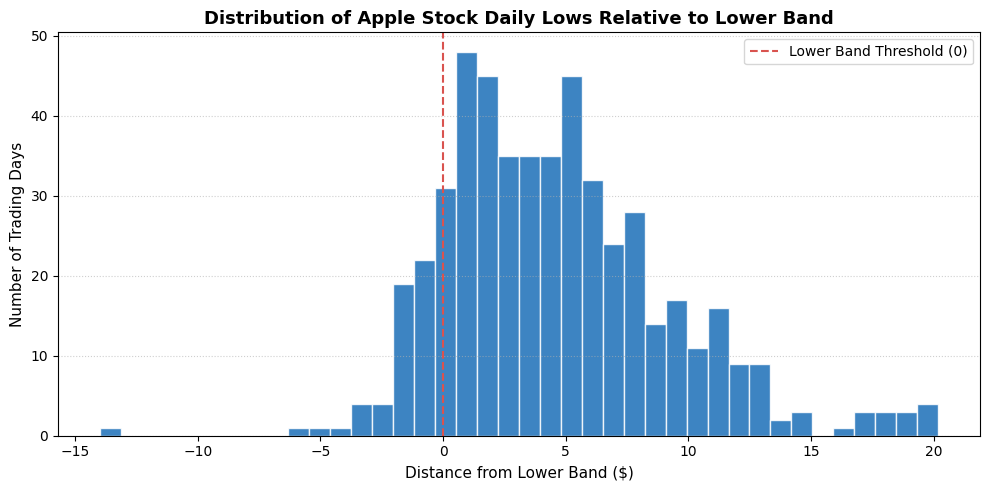

In [7]:
plt.figure(figsize=(10, 5))
plt.hist(prices["low_vs_dn"].dropna(), bins=40, color="#1B6FB8", edgecolor="white", alpha=0.85)
plt.axvline(0, color="#D9534F", linestyle="--", linewidth=1.5, label="Lower Band Threshold (0)")
plt.xlabel("Distance from Lower Band ($)", fontsize=11)
plt.ylabel("Number of Trading Days", fontsize=11)
plt.title("Distribution of Apple Stock Daily Lows Relative to Lower Band", fontsize=13, fontweight="bold")
plt.legend()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

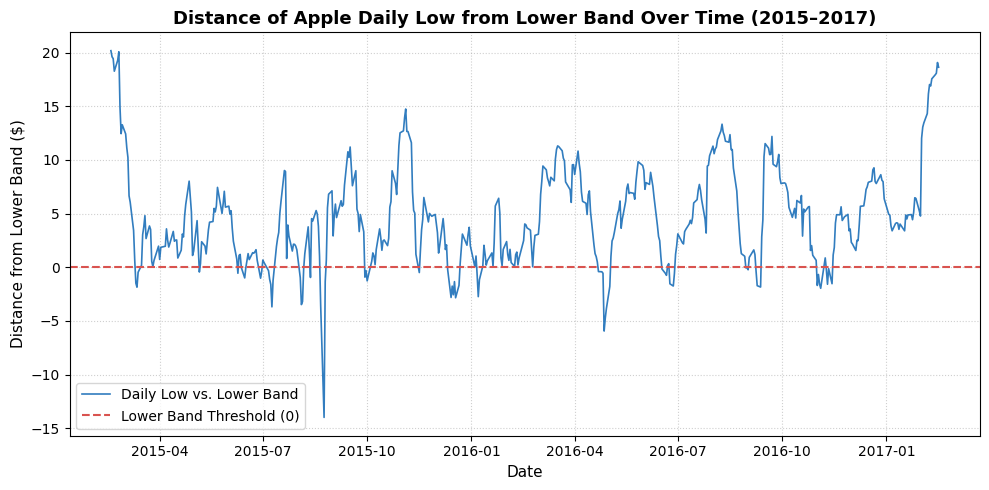

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(prices["Date"], prices["low_vs_dn"], color="#1B6FB8", linewidth=1.2, alpha=0.9, label="Daily Low vs. Lower Band")
plt.axhline(0, color="#D9534F", linestyle="--", linewidth=1.5, label="Lower Band Threshold (0)")
plt.xlabel("Date", fontsize=11)
plt.ylabel("Distance from Lower Band ($)", fontsize=11)
plt.title("Distance of Apple Daily Low from Lower Band Over Time (2015–2017)", fontsize=13, fontweight="bold")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


## 6. Financial Interpretation
* **General Support Level:** Apple's daily lowest price predominantly remains above the technical lower band, as confirmed by positive mean distances across all three observed years.
* **Skewness & Breaches:** The distribution chart reveals a right-skewed pattern, showing that breaches below the lower band (`< 0`) are relatively infrequent tail events.
* **Volatility Clustering:** The time-series chart demonstrates that negative breaches are not randomly distributed; instead, they cluster during periods of heightened downward market volatility, most notably in mid-2015.
* **Trend Progression:** The progressive increase in the annual mean distance from 2015 (`$3.80`) to 2017 (`$8.94`) reflects stronger upward momentum and reduced downward price pressure over this timeframe.

---

## 7. Limitations & Next Steps
* **Descriptive Scope:** This analysis is strictly descriptive and confined to the observed 2015–2017 historical sample. While it identifies historical frequencies and volatility clusters, it does not establish causality or predictive power.
* **Future Research Question:** *Does a breach of the lower band reliably predict a short-term positive price reversal (mean reversion) in the subsequent trading days, or does it signal sustained downward momentum?*

---

## 8. AI Disclosure
*Generative AI was utilized as a coding assistant to optimize the notebook structure, refine Matplotlib visualization formatting, and enhance the clarity of the financial commentary. Every code cell was manually reviewed, executed from a clean session, and verified. All final analytical claims reflect my independent interpretation of the dataset.*
